# Statistical Arbitrage in Crypto: Momentum and Reversal

The question I wanted to answer: are there momentum or reversal patterns in crypto prices that are still profitable once you pay realistic trading costs?

Outline:
1. Data: 4-hour prices and volumes for 10 large coins from Binance
2. Time horizon: which look-back windows show reversal and which show momentum
3. Trying to make the signals stronger: volume, residual returns, seasonality, market regimes
4. Trading costs (20 bps per trade) and how to cut turnover
5. Checking whether reversal adds anything to momentum once costs are included
6. Performance: return, volatility, Sharpe, max drawdown, alpha (with t-stat) and beta

The final strategy ended up being a multi-horizon cross-sectional momentum strategy. The reversal work is kept in as a research finding: the pattern is real, but it trades too much to survive costs.

To keep myself honest, every decision is made using 2021-2023 only (training period). I only look at 2024-2025 (test period) at the very end.

## Running the notebook

Install the packages once (cell below), then Kernel → Restart & Run All. The first run downloads the data from Binance, which takes a minute or two, and saves it to `prices_4h.csv` and `volumes_4h.csv`. After that the notebook reads from those files.

In [1]:
# Run this once to install the packages (remove the # at the start of the line)
# !pip install python-binance pandas numpy matplotlib

## 1. Data

Binance publishes its historical price data for free through a public API, so no account or API key is needed. I download it with the `python-binance` package. `client.get_historical_klines(symbol, interval, start, end)` returns candlesticks ("klines"), one row per 4-hour bar:

| Column | Meaning |
|---|---|
| `open_time` | start of the bar, in milliseconds since 1970 (converted to a date below) |
| `open`, `high`, `low`, `close` | prices during the bar |
| `volume` | number of coins traded |
| `quote_volume` | dollar (USDT) value traded, which is what I use as volume |

Some choices I made:
* 10 of the largest coins quoted in USDT, all listed on Binance before 2021.
* 4-hour bars (6 per day). Short enough to catch reversal, and the dataset stays small.
* Data starts in Nov 2020 so the 30-day look-backs are already filled in by Jan 2021.

Note: Binance.com blocks some locations (the US, Ontario, and cloud servers like Google Colab). If you get a "restricted location" error, switch `tld='com'` to `tld='us'` to use Binance.US.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from binance.client import Client as bnb_client

client = bnb_client(tld='com')   # use tld='us' if Binance.com is blocked where you are

def get_binance_px(symbol, freq, start_ts, end_ts):
    data = client.get_historical_klines(symbol, freq, start_ts, end_ts)
    columns = ['open_time','open','high','low','close','volume','close_time','quote_volume',
               'num_trades','taker_base_volume','taker_quote_volume','ignore']
    data = pd.DataFrame(data, columns=columns)
    data['open_time'] = pd.to_datetime(data['open_time'], unit='ms')   # convert milliseconds to dates
    return data

In [3]:
univ = ['BTCUSDT','ETHUSDT','BNBUSDT','XRPUSDT','ADAUSDT',
        'DOGEUSDT','SOLUSDT','DOTUSDT','LTCUSDT','LINKUSDT']
freq = '4h'

# Download once, then load from the saved CSV files on later runs
# The CSV files are saved in the notebook's working folder (printed below)
print('Working folder:', os.getcwd())

if os.path.exists('prices_4h.csv'):
    print('Found saved data, loading prices_4h.csv and volumes_4h.csv')
    px = pd.read_csv('prices_4h.csv', index_col=0, parse_dates=True)
    vol = pd.read_csv('volumes_4h.csv', index_col=0, parse_dates=True)
else:
    px, vol = {}, {}
    for x in univ:
        print('downloading', x)
        data = get_binance_px(x, freq, '2020-11-01', '2025-12-31')
        px[x] = data.set_index('open_time')['close'].astype(float)
        vol[x] = data.set_index('open_time')['quote_volume'].astype(float)
    px = pd.DataFrame(px)
    vol = pd.DataFrame(vol)
    px.to_csv('prices_4h.csv')
    vol.to_csv('volumes_4h.csv')
    print('Saved data to', os.path.abspath('prices_4h.csv'), 'and volumes_4h.csv')

# --- Clean up the time index ---
# Binance sometimes skips a bar (e.g. exchange maintenance). Build a complete list of
# every 4h timestamp from the first bar to the last one with pd.date_range, and reindex
# the prices onto it. Any bar that was missing now shows up as an empty value (NaN)
# instead of silently disappearing. This keeps every row exactly 4 hours apart, which
# matters later: shift(1) must mean "the previous 4h bar" and rolling(6) must mean "1 day".
px = px.reindex(pd.date_range(px.index[0], px.index[-1], freq=freq))

# Line the volume table up on exactly the same timestamps as the prices.
vol = vol.reindex(px.index)

# --- Returns ---
# px.shift() moves every price down one row, so each row sees the PREVIOUS bar's price.
# return = price now / price one bar ago - 1   (e.g. 105 / 100 - 1 = 0.05 = +5%)
# The first row has no previous price, and a bar next to a missing bar has nothing to
# compare to, so those returns are NaN. pandas skips NaNs in means and sums automatically.
ret = px / px.shift() - 1

# Show the last 5 rows to check the download looks right
px.tail()

Working folder: /Users/gautamkanna/Desktop/Project
downloading BTCUSDT
downloading ETHUSDT
downloading BNBUSDT
downloading XRPUSDT
downloading ADAUSDT
downloading DOGEUSDT
downloading SOLUSDT
downloading DOTUSDT
downloading LTCUSDT
downloading LINKUSDT
Saved data to /Users/gautamkanna/Desktop/Project/prices_4h.csv and volumes_4h.csv


,BTCUSDT,ETHUSDT,BNBUSDT,XRPUSDT,ADAUSDT,DOGEUSDT,SOLUSDT,DOTUSDT,LTCUSDT,LINKUSDT
2025-12-30 08:00:00,87903.89,2978.88,854.80,1.8623,0.3523,0.12457,124.30,1.824,78.04,12.49
2025-12-30 12:00:00,89016.35,2989.77,862.78,1.8776,0.3543,0.12455,125.16,1.842,78.69,12.53
2025-12-30 16:00:00,88226.16,2971.56,859.79,1.8765,0.3513,0.12331,124.71,1.830,78.17,12.43
2025-12-30 20:00:00,88485.49,2973.69,861.65,1.8776,0.3514,0.12336,125.01,1.811,78.89,12.42
2025-12-31 00:00:00,88453.04,2970.69,859.29,1.8720,0.3518,0.12312,125.82,1.813,78.11,12.39


Bars: 11317 | From 2020-11-01 00:00:00 to 2025-12-31 00:00:00


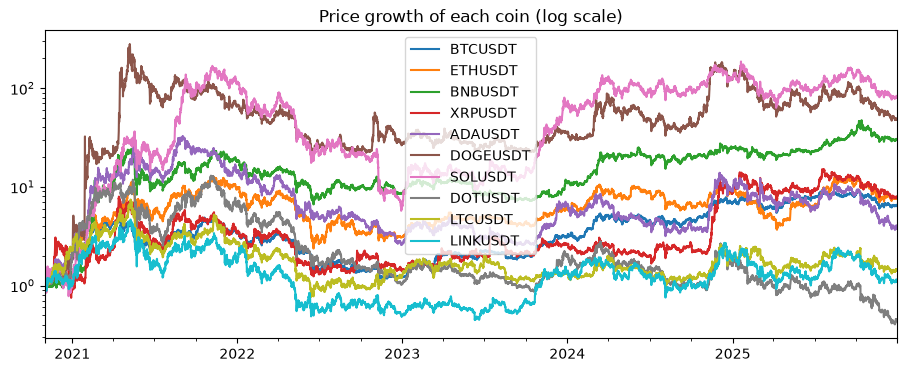

In [4]:
# Quick look at the data: number of 4h bars and the first / last date
print('Bars:', len(ret), '| From', ret.index[0], 'to', ret.index[-1])

# Growth of $1 in each coin: divide every price by the coin's first price, so all coins start at 1.
# (bfill fills any empty first values with the next real price, so the starting value is never NaN.)
# logy=True puts the y-axis on a log scale. Coins grew by very different amounts (SOL ~80x, DOT fell
# by more than half), and on a normal axis SOL would squash every other line flat near the bottom.
# On a log scale, equal % moves look equally big (1 -> 2 is the same height as 10 -> 20).
# figsize=(11,4) sets the chart size in inches: 11 wide, 4 tall.
(px / px.bfill().iloc[0]).plot(logy=True, figsize=(11,4), title='Price growth of each coin (log scale)')
plt.show()

## 2. Helper functions

* `xs_portfolio(signal)`: ranks the coins by a signal, subtracts the average rank and scales so the absolute weights add up to 1. High signal = long, low signal = short, and the portfolio is dollar-neutral.
* `backtest(port)`: gross return, turnover, and net return after costs on 4h bars. The portfolio is shifted by one bar so it only earns the *next* bar's return (no look-ahead).
* `to_daily(x)`: compounds the 4h returns into daily returns. All the statistics are calculated on these daily returns.
* `get_sharpe(x)`: Sharpe ratio from daily returns, annualized with √252.
* `compute_stats(rets)`: annual return, volatility, Sharpe, max drawdown (from the growth-of-$1 curve), and a regression on Bitcoin for beta, alpha and the alpha t-stat.

In [5]:
# Trading cost, as a fraction of every dollar traded. 1 bp (basis point) = 0.01% = 0.0001.
# I assume 20 bps for market orders:
#   7 bps commission (the exchange's fee) + 13 bps slippage (buying a bit above / selling a bit
#   below the quoted price, from crossing the bid-ask spread and moving the price).
# Example: trading $10,000 of coins costs $10,000 * 0.0020 = $20.
# backtest() uses this: net return = gross return - turnover * COST
COST = 0.0020
# Split the history into two date ranges. slice(start, end) is just a saved "from date - to date" range.
# Writing ret.loc[train] is the same as ret.loc['2021-01-01':'2023-12-31'] (both end dates included).
#   train: 2021-2023, used to test ideas and make every choice (look-backs, half-lives, weights)
#   test:  2024-2025, only used at the very end to check the strategy on data it has never seen
train = slice('2021-01-01', '2023-12-31')
test = slice('2024-01-01', '2025-12-31')

# Bitcoin's returns, used as the "market" benchmark for beta / alpha and for residual returns
btc = ret['BTCUSDT']

# Turn a signal into portfolio weights. Example for one bar, 4 coins:
#   signal:            A = +5%   B = -2%   C = +1%   D = +3%
#   1) rank:           A = 4     B = 1     C = 2     D = 3      (1 = lowest signal)
#   2) minus avg 2.5:  A = 1.5   B = -1.5  C = -0.5  D = 0.5    (positive = long, negative = short)
#   3) / sum|x| = 4:   A = 0.375 B = -0.375 C = -0.125 D = 0.125
# Result: 50% long, 50% short (dollar-neutral), and the strongest signals get the biggest weights.
def xs_portfolio(signal):
    port = signal.rank(axis=1)                              # 1) rank coins against each other in each row (bar)
    port = port.subtract(port.mean(axis=1), axis=0)         # 2) subtract the row's average rank -> longs and shorts cancel
    port = port.divide(port.abs().sum(axis=1), axis=0)      # 3) scale so total |weights| = 1 (100% of capital)
    return port.fillna(0)                                   # coins with no signal (missing data) get weight 0

def backtest(port, cost=COST):
    gross = (port.shift() * ret).sum(axis=1)
    turnover = port.diff().abs().sum(axis=1).shift()      # how much of the portfolio was traded
    net = gross - turnover * cost
    return pd.DataFrame({'gross': gross, 'net': net, 'turnover': turnover})

# --- Performance is measured on DAILY returns ---
# The backtest runs on 4h bars, but all Sharpe ratios, volatilities, drawdowns and regressions use
# daily returns: the six 4h returns in each day are compounded into one daily return, and the
# results are annualized with 252 days (the standard convention for Sharpe ratios).
# Crypto trades 365 days a year, so sqrt(365) would make every Sharpe ~20% higher; 252 is the
# more conservative choice.
DAYS = 252

def to_daily(x):
    # (1 + r1) * (1 + r2) * ... * (1 + r6) - 1  for the six 4h bars of each day
    return (1 + x).resample('D').prod() - 1

# lambda = a short, one-line function. sharpe_daily is the same as:
#     def sharpe_daily(d):
#         return d.mean() / d.std() * np.sqrt(DAYS)
sharpe_daily = lambda d: d.mean() / d.std() * np.sqrt(DAYS)   # d = daily returns
get_sharpe = lambda x: sharpe_daily(to_daily(x))              # x = 4h returns (converted to daily first)

def compute_stats(rets):
    daily = to_daily(rets)                        # 4h strategy returns -> daily returns
    btc_d = to_daily(btc).loc[daily.index]        # BTC daily returns over the same days

    stats = {}
    stats['avg'] = daily.mean() * DAYS
    stats['vol'] = daily.std() * np.sqrt(DAYS)
    stats['sharpe'] = stats['avg'] / stats['vol']

    # Max drawdown: grow $1 with the daily returns (equity curve), then find the worst
    # % fall from a previous peak. E.g. $1.50 peak -> $1.20 later = 1.20 / 1.50 - 1 = -20%.
    wealth = (1 + daily).cumprod()
    stats['max_dd'] = (wealth / wealth.cummax() - 1).min()

    # Regression on BTC (daily):  strategy = alpha + beta * BTC + noise
    # t-stat of alpha = alpha / standard error of alpha. Roughly, |t| > 2 means the alpha is
    # statistically significant (unlikely to be luck). Same numbers as statsmodels OLS would give.
    beta, alpha, t_alpha = {}, {}, {}
    for col in daily.columns:
        y = daily[col]
        b = y.cov(btc_d) / btc_d.var()
        a = y.mean() - b * btc_d.mean()                            # daily alpha
        resid = y - a - b * btc_d
        se_a = resid.std(ddof=2) * np.sqrt(1 / len(y) + btc_d.mean()**2 / ((btc_d - btc_d.mean())**2).sum())
        if resid.std() < 1e-12:                                    # e.g. BTC regressed on itself
            se_a = np.nan
        beta[col], alpha[col], t_alpha[col] = b, a * DAYS, a / se_a
    stats['beta'] = pd.Series(beta)
    stats['alpha'] = pd.Series(alpha)
    stats['alpha_tstat'] = pd.Series(t_alpha)
    stats['corr_btc'] = daily.corrwith(btc_d)
    return pd.DataFrame(stats)

## 3. Time horizon: where is reversal and where is momentum?

By time horizon I mean how far back I look to decide which coins are the "winners" and which are the "losers". With a 4-hour horizon, the winners are the coins that went up the most in the last 4 hours. With a 7-day horizon, they're the coins that went up the most over the past week.

Then the question is what those winners do next. If they keep outperforming, that's momentum. If they fall back, that's reversal. My expectation going in was reversal at short horizons (overreactions that bounce back) and momentum at longer ones (trends that continue).

For each horizon I go long the past winners and short the past losers and look at the Sharpe:
* positive Sharpe = momentum
* negative Sharpe = reversal (so the trade that makes money is the opposite one: buy losers, short winners)

I test horizons from 4 hours to 30 days. I also run a "skip" version that ignores the most recent bar (`shift(2)` instead of `shift()`). If the most recent bar is where the reversal is, skipping it should make momentum cleaner.

In [6]:
horizons = [1, 2, 3, 6, 12, 18, 42, 84, 180]   # in 4h bars: 4h, 8h, 12h, 1d, 2d, 3d, 7d, 14d, 30d

sr, sr_skip = {}, {}
for hor in horizons:
    port = xs_portfolio(ret.rolling(hor).mean())
    sr[hor] = get_sharpe(backtest(port)['gross'].loc[train])
    sr_skip[hor] = get_sharpe(backtest(port.shift())['gross'].loc[train])   # skip the most recent bar

horizon = pd.DataFrame({'sharpe': sr, 'sharpe_skip': sr_skip})
horizon.index = [f'{h*4}h' for h in horizons]
horizon

,sharpe,sharpe_skip
4h,-0.203659,0.876346
8h,0.510884,1.510026
12h,1.176638,2.170851
24h,1.396878,1.871687
48h,1.685705,1.766557
72h,1.676113,1.875161
168h,1.533602,1.599879
336h,0.926170,1.084801
720h,1.191297,1.283587


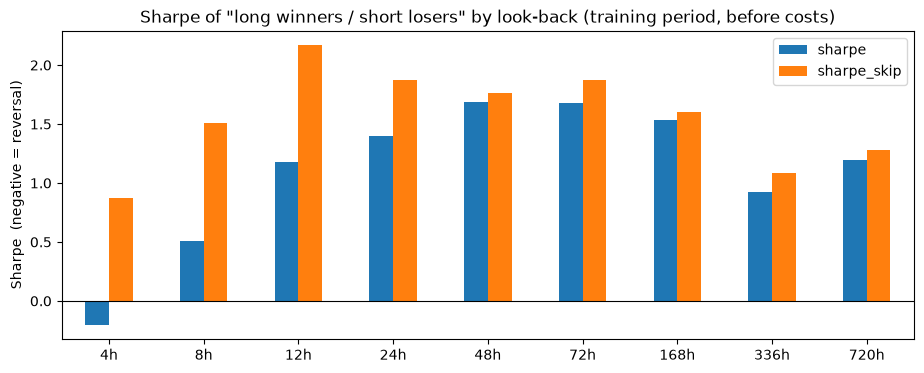

In [7]:
horizon.plot(kind='bar', figsize=(11,4), rot=0,
             title='Sharpe of "long winners / short losers" by look-back (training period, before costs)')
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('Sharpe  (negative = reversal)')
plt.show()

How I pick the two base strategies (training period only):
* Reversal: the short horizon (1 day or less) with the most negative Sharpe. The signal gets a minus sign so the strategy buys recent losers.
* Momentum: the longer horizon (1 day or more) with the highest Sharpe in the skip version.

In [8]:
short_h = [h for h in horizons if h <= 6]
long_h = [h for h in horizons if h >= 6]
rev_hor = min(short_h, key=lambda h: sr[h])
mom_hor = max(long_h, key=lambda h: sr_skip[h])
print(f'Reversal look-back: {rev_hor*4}h   Momentum look-back: {mom_hor*4}h')

rev_signal = -ret.rolling(rev_hor).mean()             # minus sign: buy losers, sell winners
mom_signal = ret.rolling(mom_hor).mean().shift()      # skip the most recent bar

port_rev = xs_portfolio(rev_signal)
port_mom = xs_portfolio(mom_signal)

Reversal look-back: 4h   Momentum look-back: 72h


**Multi-horizon momentum.** Momentum shows up at pretty much every horizon from 12 hours to 30 days, so instead of betting on one window I also tried averaging each coin's momentum rank over 3, 7, 14 and 30 days. The signal is steadier and changes more slowly, which should help a lot once costs come in (Section 8).

In [9]:
multi_signal = sum(ret.rolling(h).mean().shift().rank(axis=1) for h in [18, 42, 84, 180])   # 3d, 7d, 14d, 30d
port_mom_multi = xs_portfolio(multi_signal)
print('Multi-horizon momentum Sharpe (train, gross):', round(get_sharpe(backtest(port_mom_multi)['gross'].loc[train]), 2))

Multi-horizon momentum Sharpe (train, gross): 1.66


## 4. Volume: is reversal stronger on quiet moves?

The idea: price moves driven by uninformed trading (no news, not much activity) should reverse, while moves on heavy volume are more likely to carry real information and stick.

To test it I compare each coin's recent volume with its normal volume (30-day average). Each bar I split the coins into a low-volume half and a high-volume half and run the reversal strategy on each half separately.

In [10]:
rel_vol = vol.rolling(rev_hor).mean() / vol.rolling(180).mean()   # recent volume vs. normal volume
low_vol = rel_vol.rank(axis=1, pct=True) <= 0.5                        # True for the quieter half of coins

port_rev_lowvol = xs_portfolio(rev_signal.where(low_vol))
port_rev_highvol = xs_portfolio(rev_signal.where(~low_vol))

volume_test = pd.Series({
    'Reversal - all coins': get_sharpe(backtest(port_rev)['gross'].loc[train]),
    'Reversal - low volume': get_sharpe(backtest(port_rev_lowvol)['gross'].loc[train]),
    'Reversal - high volume': get_sharpe(backtest(port_rev_highvol)['gross'].loc[train]),
})
volume_test.to_frame('sharpe (train, gross)')

,"sharpe (train, gross)"
Reversal - all coins,0.253920
Reversal - low volume,1.696310
Reversal - high volume,-0.506753


## 5. Residual returns

Most coins move with Bitcoin. If I strip that common move out, what's left (the residual) might mean-revert more cleanly. I use a rolling 30-day beta to BTC:

`beta = correlation × (coin vol / BTC vol)` and `residual = ret − beta × BTC ret`

and rebuild the reversal and momentum signals on the residuals.

In [11]:
corr = ret.rolling(180).corr(btc)
vols = ret.rolling(180).std()
beta = (corr * vols).divide(vols['BTCUSDT'], axis=0).shift()   # shift: only use beta known before the bar
resid = ret - beta.multiply(btc, axis=0)

port_rev_resid = xs_portfolio(-resid.rolling(rev_hor).mean())
port_mom_resid = xs_portfolio(resid.rolling(mom_hor).mean().shift())

resid_test = pd.Series({
    'Reversal - raw': get_sharpe(backtest(port_rev)['gross'].loc[train]),
    'Reversal - residual': get_sharpe(backtest(port_rev_resid)['gross'].loc[train]),
    'Momentum - raw': get_sharpe(backtest(port_mom)['gross'].loc[train]),
    'Momentum - residual': get_sharpe(backtest(port_mom_resid)['gross'].loc[train]),
})
resid_test.to_frame('sharpe (train, gross)')

,"sharpe (train, gross)"
Reversal - raw,0.253920
Reversal - residual,0.088714
Momentum - raw,1.875161
Momentum - residual,1.637480


## 6. Seasonality

**6a. When do the strategies make money?** Weekday vs. weekend (institutions mostly trade on weekdays) and time of day in UTC. For reference, the US stock market opens at 13:30-14:30 UTC.

In [12]:
rev_gross = backtest(port_rev)['gross'].loc[train]
mom_gross = backtest(port_mom)['gross'].loc[train]
rev_daily = to_daily(rev_gross)
mom_daily = to_daily(mom_gross)

weekend = np.where(rev_daily.index.dayofweek >= 5, 'weekend', 'weekday')
pd.DataFrame({'reversal': rev_daily.groupby(weekend).apply(sharpe_daily),
              'momentum': mom_daily.groupby(weekend).apply(sharpe_daily)})

,reversal,momentum
weekday,0.335887,1.729079
weekend,0.016851,2.351469


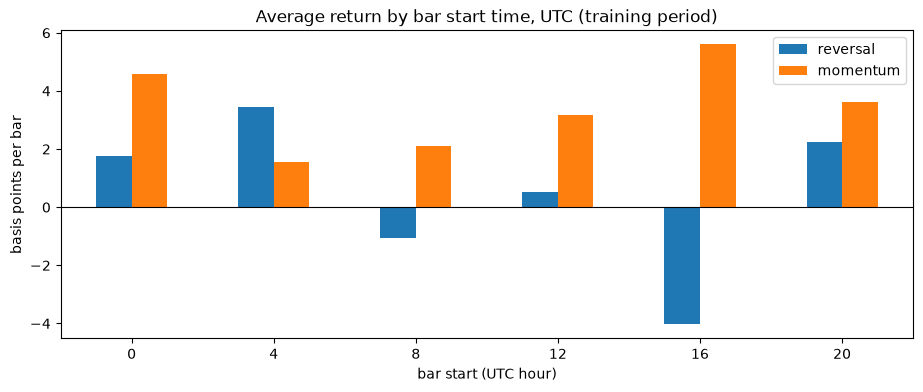

In [13]:
by_hour = pd.DataFrame({'reversal': rev_gross.groupby(rev_gross.index.hour).mean(),
                        'momentum': mom_gross.groupby(mom_gross.index.hour).mean()}) * 10000
by_hour.plot(kind='bar', rot=0, figsize=(11,4), title='Average return by bar start time, UTC (training period)')
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('basis points per bar')
plt.xlabel('bar start (UTC hour)')
plt.show()

**6b. Same-time-of-day momentum.** Do coins that tend to do well at a certain time of day keep doing well at that time?

Signal: each coin's average return in the same 4h slot of the day over the past 30 days. There are 6 bars a day, and I'm predicting the next bar, so the same slot yesterday is `shift(5)`, the day before is `shift(11)`, and so on.

In [14]:
seasonal_signal = sum(ret.shift(5 + 6*k) for k in range(30)) / 30
port_season = xs_portfolio(seasonal_signal)
print('Seasonality Sharpe (train, gross):', round(get_sharpe(backtest(port_season)['gross'].loc[train]), 2))

Seasonality Sharpe (train, gross): 2.94


## 7. Market regimes: more reversal when things are stressed?

My hypothesis was that reversal should be stronger when markets are dislocated, since that's when liquidity providers get paid the most. I measure dislocation with return dispersion (how differently the coins moved over the last day) and split the training period into low, medium and high thirds.

In [15]:
dispersion = ret.std(axis=1).resample('D').mean().shift()   # previous day's average dispersion (known in advance)
regime = pd.qcut(dispersion.loc[train], 3, labels=['low', 'medium', 'high'])
rev_daily.groupby(regime).apply(sharpe_daily).to_frame('reversal sharpe by dispersion regime')

,reversal sharpe by dispersion regime
low,1.260307
medium,0.154248
high,0.051246


## 8. Trading costs

Every change to the portfolio costs 20 bps on the amount traded. Short-term strategies trade a lot, so this is where most of them die.

To trade less I smooth the portfolio with `port.ewm(halflife).mean()`, which only moves part of the way toward the new target each bar. Longer half-life = less trading, but a slower signal. I tried a range of half-lives on every strategy.

In [16]:
candidates = {
    'Reversal': port_rev,
    'Reversal - low volume': port_rev_lowvol,
    'Reversal - residual': port_rev_resid,
    'Momentum': port_mom,
    'Momentum - residual': port_mom_resid,
    'Momentum - multi-horizon': port_mom_multi,
    'Seasonality': port_season,
}
halflives = [0, 1, 3, 6, 12, 24, 48]   # in 4h bars: 24 = 4 days, 48 = 8 days

net_sr, turnover = {}, {}
for name, port in candidates.items():
    net_sr[name], turnover[name] = {}, {}
    for hl in halflives:
        smooth = port if hl == 0 else port.ewm(halflife=hl).mean()
        res = backtest(smooth).loc[train]
        net_sr[name][hl] = get_sharpe(res['net'])
        turnover[name][hl] = res['turnover'].mean()

net_sr = pd.DataFrame(net_sr).T
net_sr.columns.name = 'half-life (bars)'
print('Net Sharpe after 20 bps costs (training period):')
net_sr

Net Sharpe after 20 bps costs (training period):


half-life (bars),0,1,3,6,12,24,48
Reversal,-13.388848,-8.479181,-6.046314,-5.014005,-4.087896,-3.251851,-2.464918
Reversal - low volume,-17.866825,-12.722199,-8.308780,-6.227891,-4.572921,-3.283963,-2.282141
Reversal - residual,-13.891037,-8.799121,-6.118447,-5.016376,-4.089029,-3.271198,-2.465595
Momentum,-1.784984,-0.684051,-0.305678,-0.292498,-0.289345,-0.240803,-0.146745
Momentum - residual,-1.909251,-0.718930,-0.245238,-0.201425,-0.155658,-0.052015,0.058364
Momentum - multi-horizon,-1.007528,-0.029673,0.295899,0.321107,0.314864,0.341441,0.361103
Seasonality,-13.104976,-8.207225,-3.639869,-1.789140,-0.753230,-0.159272,0.136690


In [17]:
print('Average turnover per bar (fraction of the portfolio traded):')
pd.DataFrame(turnover).T

Average turnover per bar (fraction of the portfolio traded):


,0,1,3,6,12,24,48
Reversal,1.335012,0.559032,0.214476,0.111059,0.056505,0.028507,0.014326
Reversal - low volume,1.557357,0.664709,0.247498,0.124984,0.062104,0.030733,0.015228
Reversal - residual,1.333613,0.558086,0.214390,0.111025,0.056498,0.028505,0.014324
Momentum,0.333443,0.192153,0.108400,0.072099,0.044224,0.025001,0.013359
Momentum - residual,0.332225,0.191924,0.108285,0.072163,0.044272,0.025023,0.013369
Momentum - multi-horizon,0.249006,0.134117,0.071540,0.047219,0.030114,0.018394,0.010781
Seasonality,1.289376,0.546825,0.203769,0.103682,0.052401,0.026534,0.013508


Final picks: the best reversal-type strategy and the best momentum-type strategy (plain, residual, multi-horizon or seasonality), ranked by net Sharpe in the training period.

In [18]:
rev_names = ['Reversal', 'Reversal - low volume', 'Reversal - residual']
mom_names = ['Momentum', 'Momentum - residual', 'Momentum - multi-horizon', 'Seasonality']

final = {}
for label, names in [('reversal', rev_names), ('momentum', mom_names)]:
    best_name = net_sr.loc[names].max(axis=1).idxmax()
    best_hl = net_sr.loc[best_name].idxmax()
    port = candidates[best_name]
    final[label] = port if best_hl == 0 else port.ewm(halflife=best_hl).mean()
    print(f'{label}: {best_name}, half-life {best_hl} -> net Sharpe {net_sr.loc[best_name, best_hl]:.2f}')

strat = pd.DataFrame({label: backtest(port)['net'] for label, port in final.items()}).loc['2021-01-01':]

reversal: Reversal - low volume, half-life 48 -> net Sharpe -2.28
momentum: Momentum - multi-horizon, half-life 48 -> net Sharpe 0.36


In [19]:
# How much do costs take away? Sharpe of the final strategies before and after costs (training period)
pd.DataFrame({label: {'before costs': get_sharpe(backtest(port)['gross'].loc[train]),
                      'after 20 bps': get_sharpe(backtest(port)['net'].loc[train]),
                      'after 7 bps (limit orders)': get_sharpe(backtest(port, cost=0.0007)['net'].loc[train])}
              for label, port in final.items()}).round(2)

,reversal,momentum
before costs,-0.50,0.58
after 20 bps,-2.28,0.36
after 7 bps (limit orders),-1.12,0.50


## 9. Does reversal add anything?

Before costs, reversal and momentum are almost uncorrelated, so in principle a mix of the two should be better than either alone. I check this with mean-variance weights (`inverse(covariance) @ mean`) estimated on the training period only.

A strategy only gets a weight if it made money after costs in training. Shorting a losing strategy makes no sense, so it isn't allowed. Reversal loses money after costs, so it gets zero weight and the final portfolio is the multi-horizon momentum strategy on its own.

In [20]:
print('Correlation between the strategies (train):')
print(strat.loc[train].corr().round(2))

def optimal_weights(sigma, mu):
    wgt = np.linalg.inv(sigma) @ mu
    wgt = wgt / np.abs(wgt).sum()
    return wgt

cols = ['reversal', 'momentum']
daily_train = to_daily(strat.loc[train, cols])

# Only strategies that made money after costs in training are allowed in.
# (Otherwise the optimizer would try to short a losing strategy, which makes no sense.)
keep = [c for c in cols if daily_train[c].mean() > 0]
wgt = pd.Series(0.0, cols)
if len(keep) == 1:
    wgt[keep[0]] = 1.0
elif len(keep) == 2:
    w = optimal_weights(daily_train[keep].cov(), daily_train[keep].mean())
    wgt[keep] = np.clip(w, 0, None) / np.clip(w, 0, None).sum()
print('Strategies with positive net returns in training:', keep)
print('\nWeights:'); print(wgt.round(2))

# With 0% on reversal, the final portfolio is the momentum strategy
strat['final'] = (strat[cols] * wgt).sum(axis=1)

# Scale it to 20% yearly volatility (a typical target for a hedge-fund strategy),
# using the training-period volatility so the test period isn't used.
lev = 0.20 / (to_daily(strat['final'].loc[train]).std() * np.sqrt(DAYS))
strat['final_20vol'] = strat['final'] * lev
print(f'\nLeverage for 20% vol: {lev:.2f}x')

Correlation between the strategies (train):
          reversal  momentum
reversal      1.00     -0.11
momentum     -0.11      1.00
Strategies with positive net returns in training: ['momentum']

Weights:
reversal    0.0
momentum    1.0
dtype: float64

Leverage for 20% vol: 1.35x


## 10. Performance

All numbers come from **daily** returns (the 4h returns compounded into days) and are annualized with 252 days.
* **Base case: 20 bps costs.** The 7 bps line is a sensitivity test only. It assumes every limit order fills at the quoted price, which isn't guaranteed: orders can miss, and the ones that fill are often the ones you'd rather not get (adverse selection). So I treat it as an optimistic scenario, not the headline result.
* avg / vol / sharpe: annualized return (daily mean × 252), volatility and Sharpe ratio
* max_dd: worst peak-to-trough fall in the growth-of-$1 curve
* beta / alpha / alpha_tstat: from regressing daily strategy returns on daily BTC returns. Alpha is the return left over after removing Bitcoin exposure. A t-stat above roughly 2 would mean the alpha is statistically significant.
* The reversal strategy is shown for reference only. It isn't part of the final portfolio.

In [21]:
# Sensitivity test: the same final strategy at 7 bps (limit orders). This is an optimistic case,
# since it assumes every limit order fills at the quoted price. The 20 bps result is the base case.
strat['final (7 bps, optimistic)'] = sum(backtest(final[c], cost=0.0007)['net'] * wgt[c] for c in cols)
strat['BTC buy & hold'] = btc
report = strat[['final', 'final_20vol', 'final (7 bps, optimistic)', 'reversal', 'BTC buy & hold']]

print('TRAINING period 2021-2023 (used to build the strategy)')
display(compute_stats(report.loc[train]).round(3))

print('TEST period 2024-2025 (never seen before, the honest result)')
display(compute_stats(report.loc[test]).round(3))

TRAINING period 2021-2023 (used to build the strategy)


,avg,vol,sharpe,max_dd,beta,alpha,alpha_tstat,corr_btc
final,0.053,0.148,0.361,-0.253,-0.008,0.055,0.779,-0.029
final_20vol,0.073,0.200,0.363,-0.330,-0.011,0.075,0.782,-0.029
"final (7 bps, optimistic)",0.075,0.148,0.504,-0.210,-0.008,0.077,1.077,-0.029
reversal,-0.059,0.026,-2.282,-0.231,0.003,-0.060,-4.810,0.055
BTC buy & hold,0.232,0.539,0.431,-0.766,1.000,0.000,NaN,1.000


TEST period 2024-2025 (never seen before, the honest result)


,avg,vol,sharpe,max_dd,beta,alpha,alpha_tstat,corr_btc
final,0.047,0.115,0.411,-0.131,-0.024,0.055,0.817,-0.081
final_20vol,0.064,0.155,0.413,-0.173,-0.032,0.075,0.821,-0.081
"final (7 bps, optimistic)",0.068,0.115,0.592,-0.117,-0.024,0.076,1.125,-0.081
reversal,-0.045,0.017,-2.632,-0.125,0.005,-0.047,-4.689,0.125
BTC buy & hold,0.333,0.397,0.838,-0.320,1.000,-0.000,NaN,1.000


In [22]:
print('Sharpe ratio in each year:')
report.groupby(report.index.year).apply(lambda x: x.apply(get_sharpe)).round(2)

Sharpe ratio in each year:


,final,final_20vol,"final (7 bps, optimistic)",reversal,BTC buy & hold
2021,0.66,0.66,0.76,-2.17,0.82
2022,-0.26,-0.26,-0.05,-3.06,-1.07
2023,0.45,0.45,0.63,-2.31,1.95
2024,0.44,0.44,0.60,-2.06,1.46
2025,0.38,0.39,0.59,-3.46,0.06


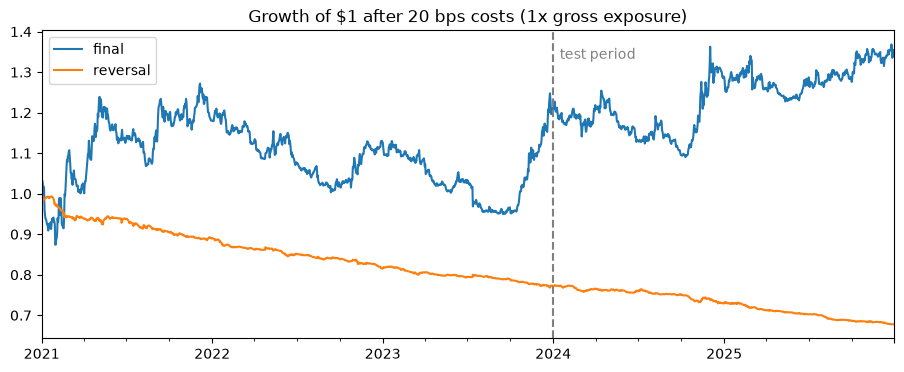

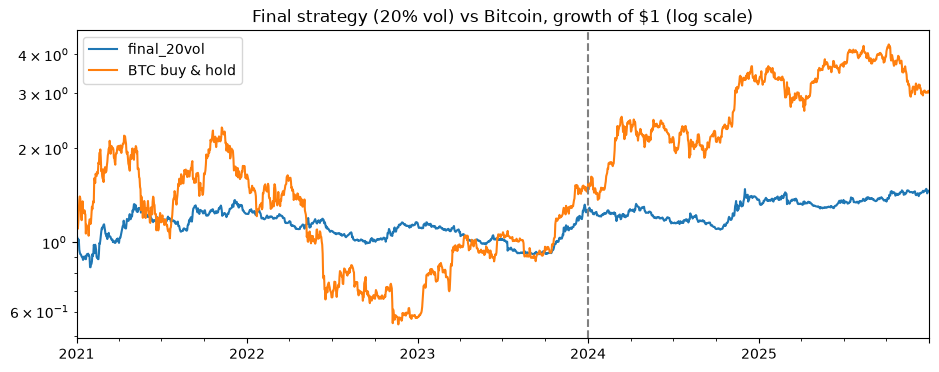

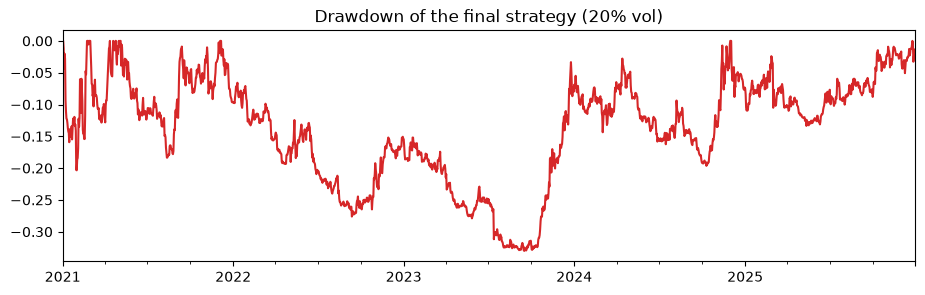

In [23]:
# Growth of $1 (equity curves), built from daily returns
wealth = (1 + to_daily(report)).cumprod()

ax = wealth[['final', 'reversal']].plot(figsize=(11,4), title='Growth of $1 after 20 bps costs (1x gross exposure)')
ax.axvline(pd.Timestamp('2024-01-01'), color='gray', linestyle='--')
ax.text(pd.Timestamp('2024-01-15'), ax.get_ylim()[1]*0.95, 'test period', color='gray')
plt.show()

ax = wealth[['final_20vol', 'BTC buy & hold']].plot(figsize=(11,4), logy=True,
        title='Final strategy (20% vol) vs Bitcoin, growth of $1 (log scale)')
ax.axvline(pd.Timestamp('2024-01-01'), color='gray', linestyle='--')
plt.show()

w = wealth['final_20vol']
(w / w.cummax() - 1).plot(figsize=(11,3), color='tab:red', title='Drawdown of the final strategy (20% vol)')
plt.show()

## 11. Findings

(Numbers below are from my run on Binance data from Nov 2020 to Dec 2025. Sharpes are calculated on daily returns × √252. The next cell prints the main numbers from the live results.)

**Time horizon.** Only the 4h look-back showed reversal, and it was weak (Sharpe -0.20 for long winners). From 8 hours all the way to 30 days it was momentum, strongest between 2 and 7 days (Sharpe around 1.5 to 1.7 before costs). Skipping the most recent bar made momentum stronger at every horizon, e.g. 12h went from 1.18 to 2.17, so the latest bar is where the reversal sits.

**Volume.** Reversal is concentrated in quiet coins: Sharpe 1.70 on the low-volume half vs -0.51 on the high-volume half. That's consistent with the idea that moves without new information tend to reverse.

**Residual returns.** Taking out Bitcoin didn't help (reversal 0.25 to 0.09, momentum 1.88 to 1.64). I think this is because the portfolios are already dollar-neutral across 10 coins that all move with BTC, so most of the market move cancels out anyway.

**Seasonality.** Same-time-of-day momentum was the strongest signal I found before costs (Sharpe 2.94). Momentum also worked better on weekends (2.35) than weekdays (1.73), while reversal only showed up on weekdays (0.34 vs 0.02).

**Market regimes.** This went the opposite way from what I expected. Reversal was strongest when dispersion was low (1.26) and almost disappeared in medium and high dispersion (0.15 and 0.05).

**Costs.** This was the deciding factor. The 4h reversal strategy turns over about 134% of the portfolio every bar, so at 20 bps it ends up with a Sharpe around -13. Even with 8-day smoothing, none of the reversal or seasonality versions made money after costs. Multi-horizon momentum with an 8-day half-life trades about 1% per bar and kept a net Sharpe of 0.36 in training.

**Reversal as a research finding.** Before costs, low-volume reversal and multi-horizon momentum are close to uncorrelated (-0.09) and a 50/50 mix has a Sharpe around 2.5. The low-volume reversal pattern makes economic sense, but with this much turnover it can't be traded at 20 bps, so it gets no weight in the final portfolio.

**Final strategy, out of sample (2024-2025).** Multi-horizon cross-sectional momentum, 20 bps base case:

| Test 2024-2025 | Final (20 bps) | 7 bps (optimistic) | Bitcoin |
|---|---|---|---|
| Annual return | 4.7% | 6.8% | 33.3% |
| Volatility | 11.5% | 11.5% | 39.7% |
| Sharpe | 0.41 | 0.59 | 0.84 |
| Max drawdown | -13.1% | -11.7% | -32.0% |
| Beta to BTC | -0.02 | -0.02 | 1.00 |
| Alpha t-stat | 0.82 | 1.13 | - |

The test-period Sharpe (0.41) was in line with training (0.36), so the result didn't fall apart on new data. It was positive in 4 of the 5 years, with 2022 the only losing year. It's market-neutral (correlation with BTC -0.08), so it's something you'd hold alongside crypto rather than instead of it.

**But the alpha is not statistically significant.** The alpha t-stat is 0.82 in the test period and 1.08 over the full 2021-2025 sample, well short of 2. With a Sharpe around 0.4, you'd need something like 25 years of data before a t-stat of 2 would be expected, so five years can't prove it either way. The honest conclusion is that the strategy is consistent and survives costs out of sample, but the evidence is not strong enough to rule out luck.

Overall: there are strong short-term patterns in crypto (low-volume reversal, intraday seasonality, short-horizon momentum), but at 20 bps a trade only the slow signals survive. Trading less mattered more than finding a stronger signal.

In [24]:
t = compute_stats(report.loc[test])
print(f"1. Reversal appears at look-backs of {[i for i in horizon.index if horizon.loc[i,'sharpe'] < 0]}, "
      f"momentum at {[i for i in horizon.index if horizon.loc[i,'sharpe'] > 0]}.")
print(f"2. Reversal Sharpe on low-volume coins {volume_test.iloc[1]:.2f} vs high-volume coins {volume_test.iloc[2]:.2f}.")
print(f"3. Reversal Sharpe on raw returns {resid_test.iloc[0]:.2f} vs residual returns {resid_test.iloc[1]:.2f}.")
print(f"4. After 20 bps costs, the best training net Sharpes are: reversal "
      f"{net_sr.loc[rev_names].max().max():.2f}, momentum {net_sr.loc[mom_names].max().max():.2f}.")
print(f"5. Test period (2024-2025), final strategy after 20 bps: return {t.loc['final','avg']:.1%}, "
      f"Sharpe {t.loc['final','sharpe']:.2f}, max drawdown {t.loc['final','max_dd']:.1%}, "
      f"beta to BTC {t.loc['final','beta']:.2f}, alpha t-stat {t.loc['final','alpha_tstat']:.2f}.")

1. Reversal appears at look-backs of ['4h'], momentum at ['8h', '12h', '24h', '48h', '72h', '168h', '336h', '720h'].
2. Reversal Sharpe on low-volume coins 1.70 vs high-volume coins -0.51.
3. Reversal Sharpe on raw returns 0.25 vs residual returns 0.09.
4. After 20 bps costs, the best training net Sharpes are: reversal -2.28, momentum 0.36.
5. Test period (2024-2025), final strategy after 20 bps: return 4.7%, Sharpe 0.41, max drawdown -13.1%, beta to BTC -0.02, alpha t-stat 0.82.


### Limitations
* Survivorship bias: these are coins that are big today. A cleaner test would build the universe from information available at each date (e.g. the top coins by trailing volume each month, including ones that later collapsed or were delisted).
* Only 10 coins. The ranking is coarse and the results depend on a small cross-section.
* 20 bps is a flat estimate. Real slippage depends on size.
* The 7 bps case assumes limit orders always fill at the quoted price. Fill rates and adverse selection aren't modeled.
* I assume every coin can be shorted for free. In practice that would be done with perpetual futures, which charge funding.
* Trades are assumed to fill at the close of each 4h bar.

### Next steps
* Expand the universe to 20-30+ coins and see if the momentum result holds.
* Build the universe point-in-time to remove survivorship bias.
* Model limit-order fills properly before relying on the 7 bps result.
* Seasonality and low-volume reversal are strong before costs. Worth trying to trade them only when the expected edge is bigger than the cost.